# 06a validate

Step 6 of the guide has two halves. This notebook is the validator's half: it trains nothing and reads the test scores that steps 4 and 5 saved. The ablations that need new training runs are notebook 06b.

| check | question it answers | guide item | talk it tests |
|---|---|---|---|
| paired bootstrap | is the transformer's lead over XGBoost larger than the noise? | 95% CI on the difference | WF: transformer beats the feature model |
| monthly stability | does recall at a fixed cutoff hold over the six test months? | time stability | Wealthsimple: drift monitoring |
| PSI per token field | did the input distribution move between the train and test periods? | PSI, train vs test | Wealthsimple: input data quality |
| subgroups | where is each model weak: category, young cards, cardholder groups? | per-group recall | WF: long history is the driver, so short history is the risk |
| error analysis | what does each model catch that the other misses? | 20 + 20 with decode() | what the sequence model actually learned |
| ceiling | are all scores near perfect because Sparkov's fraud is rule-generated? | synthetic-data caveat | guide: read the fixed-alert-rate gaps, not the levels |

Both models are compared at the same alert rate (0.6% of test rows), with one cutoff fixed on the whole test set, the way a deployed threshold is. Seed 0 of each model is the subject of the row-level checks; the bootstrap and the seed-pair table show how much seed noise there is.

In [1]:
import os, sys, glob, shutil
try:
    from google.colab import drive, userdata                      # Colab: mount Drive, pull the repo, sync new notebooks to Drive
    drive.mount("/content/drive")
    tok = userdata.get("GH_TOKEN")
    if not os.path.exists("/content/transaction-fm"):
        !git clone -q https://{tok}@github.com/lb603487485/transaction-fm.git /content/transaction-fm
    else:
        !cd /content/transaction-fm && git pull -q
    %pip install -q datasets xgboost
    %cd /content/transaction-fm
except ImportError:                                               # laptop: this notebook is the repo copy; data under $TFM_ROOT
    here = os.getcwd()
    while not os.path.isdir(os.path.join(here, "src", "tfm")):
        assert here != os.path.dirname(here), "run this notebook from inside the transaction-fm repo"
        here = os.path.dirname(here)
    %cd {here}
sys.path.insert(0, os.path.abspath("src"))
from tfm.runtime import root, describe, on_colab
ROOT = root()
os.makedirs(f"{ROOT}/notebooks", exist_ok=True)
if on_colab():
    for f in glob.glob("notebooks/*.ipynb"):                      # new notebooks from the repo appear in Drive
        dst = f"{ROOT}/notebooks/{os.path.basename(f)}"
        if not os.path.exists(dst):
            shutil.copy(f, dst); print("new notebook in Drive:", os.path.basename(f))
import tfm
print("tfm ok |", describe(), "| ROOT =", ROOT)

/Users/evolin1/Desktop/AICoding/MLProject/transaction-fm
tfm ok | {'where': 'laptop', 'gpu': None, 'device': 'cpu', 'accelerator': 'mps', 'fp16': False, 'machine': 'Darwin arm64 12 cores'} | ROOT = /Users/evolin1/Desktop/AICoding/MLProject/transaction-fm


## Stage 6a-1: load the test rows and the saved scores

In [2]:
import json, time, os, numpy as np, pandas as pd
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
from tfm.tokenizer import TransactionTokenizer
from tfm.baseline import build_features
from tfm.metrics import evaluate_scores
from tfm.validate import (bootstrap_diff, monthly_metrics, psi_by_field, subgroup_metrics, disagreements,
                          history_length, history_bucket, global_cutoff)

P, PRE, RES = f"{ROOT}/data/processed", f"{ROOT}/pretrain/best", f"{ROOT}/results"
os.makedirs(RES, exist_ok=True)
df = pd.read_parquet(f"{P}/transactions.parquet")
cards = pd.read_parquet(f"{P}/cards.parquet")
tok = TransactionTokenizer.load(f"{PRE}/tokenizer.json")
ids_all = tok.encode(df)
FIELDS = ["TX"] + (["DT"] if tok.config["use_dt"] else []) + ["HOUR", "CAT", "MER", "AMT"] + (["DIST"] if tok.config["use_dist"] else [])
card, split, fraud = df["card_id"].to_numpy(), df["split"].to_numpy(), df["is_fraud"].to_numpy()
te = split == "test"; yt, ct = fraud[te], card[te]; test = df[te].reset_index(drop=True)
ALERT = 0.006

MODELS = {"transformer": "finetune/pretrained_H12/seed{k}", "transformer scratch": "finetune/scratch_H12/seed{k}",
          "xgboost": "baseline/full/seed{k}", "xgboost current-only": "baseline/current/seed{k}"}
scores = {}
for name, pat in MODELS.items():
    scores[name] = []
    for k in (0, 1, 2):
        path = f"{ROOT}/{pat.format(k=k)}/test_scores.npy"
        if os.path.exists(path):
            p = np.load(path); assert len(p) == len(yt), (name, k, len(p), len(yt)); scores[name].append(p)
print({n: len(v) for n, v in scores.items()}, "seeds loaded |", f"{len(yt):,} test rows, {int(yt.sum()):,} fraud")
A, B = scores["transformer"][0], scores["xgboost"][0]                 # the pair every row-level check uses
print("seed 0 at 0.6% alerts:", {n: round(evaluate_scores(yt, v[0], ct, ALERT)["recall_at_alert"], 3) for n, v in scores.items() if v})

{'transformer': 3, 'transformer scratch': 3, 'xgboost': 3, 'xgboost current-only': 3} seeds loaded | 555,719 test rows, 2,145 fraud
seed 0 at 0.6% alerts: {'transformer': 0.988, 'transformer scratch': 0.945, 'xgboost': 0.978, 'xgboost current-only': 0.807}


## Stage 6a-2: is the lead real? Paired bootstrap on the same test rows

`bootstrap_diff` resamples whole cards (all of a card's test rows go in or out together) 1,000 times and recomputes metric(transformer) minus metric(XGBoost) each time. Card resampling, not row resampling: a card's transactions are correlated, and a row bootstrap would make the interval look narrower than it is. A 95% interval that excludes zero is the "statistically meaningful" the guide asks for; the seed-pair table shows the same difference across the three seed pairings as a second, cheaper view of the noise.

In [3]:
t0 = time.time()
boot = bootstrap_diff(yt, A, B, ct, alert_rate=ALERT, n_boot=1000, seed=0, unit="card")
print(f"bootstrap: {boot['pr_auc']['n_boot']} card resamples in {time.time() - t0:.0f} s")
display(pd.DataFrame(boot).T.rename_axis("transformer minus xgboost")[["diff", "ci_low", "ci_high", "n_boot"]].style.format({"diff": "{:+.4f}", "ci_low": "{:+.4f}", "ci_high": "{:+.4f}"}))
pairs = []
for k in range(min(len(scores["transformer"]), len(scores["xgboost"]))):
    ma, mb = evaluate_scores(yt, scores["transformer"][k], ct, ALERT), evaluate_scores(yt, scores["xgboost"][k], ct, ALERT)
    pairs.append({"seed": k, **{f"{m} diff": ma[m] - mb[m] for m in ("pr_auc", "recall_at_alert", "fp_ratio")}})
pairs = pd.DataFrame(pairs); display(pairs.style.format("{:+.4f}", subset=[c for c in pairs if c != "seed"]).hide(axis="index"))
for m in ("pr_auc", "recall_at_alert", "fp_ratio"):
    b = boot[m]; verdict = "excludes zero" if (b["ci_low"] > 0 or b["ci_high"] < 0) else "includes zero"
    print(f"{m:16s} {b['diff']:+.4f}  95% CI [{b['ci_low']:+.4f}, {b['ci_high']:+.4f}]  {verdict}")

bootstrap: 1000 card resamples in 545 s


,diff,ci_low,ci_high,n_boot
transformer minus xgboost,,,,
pr_auc,+0.0106,+0.0059,+0.0156,1000
recall_at_alert,+0.0103,+0.0039,+0.0163,1000
fp_ratio,-0.0165,-0.0265,-0.0065,1000


seed,pr_auc diff,recall_at_alert diff,fp_ratio diff
0,+0.0106,+0.0103,-0.0165
1,+0.0101,+0.0126,-0.0202
2,+0.0109,+0.0098,-0.0157


pr_auc           +0.0106  95% CI [+0.0059, +0.0156]  excludes zero
recall_at_alert  +0.0103  95% CI [+0.0039, +0.0163]  excludes zero
fp_ratio         -0.0165  95% CI [-0.0265, -0.0065]  excludes zero


## Stage 6a-3: stability over time and input drift

Two separate questions. First the output side: cut the test period by month, keep the cutoff fixed, and read alert rate, recall and FP ratio per month; a model whose alerts pile up in one month or whose recall decays is a different operational risk from one that is merely a bit worse. Then the input side: PSI of every token field between the train period and the test period, the drift check Wealthsimple runs on the data before it reaches the model. PSI below 0.1 is usually read as stable, 0.1 to 0.25 as a moderate shift, above 0.25 as a major shift.

month,n,n_fraud,fraud_rate,alert_rate tra,recall_at_cutoff tra,fp_ratio tra,pr_auc tra,alert_rate xgb,recall_at_cutoff xgb,fp_ratio xgb,pr_auc xgb
2020-06,"30,058",133,0.44%,0.006487,0.992481,0.477273,0.994220,0.007120,0.984962,0.633588,0.981335
2020-07,"85,848",321,0.37%,0.005929,0.975078,0.626198,0.977436,0.006081,0.959502,0.694805,0.961291
2020-08,"88,759",415,0.47%,0.006658,0.995181,0.430993,0.992664,0.006715,0.985542,0.457213,0.980739
2020-09,"69,533",340,0.49%,0.007665,0.991176,0.581602,0.990018,0.007018,0.979412,0.465465,0.981857
2020-10,"69,348",384,0.55%,0.008306,0.984375,0.523810,0.981410,0.007830,0.981771,0.440318,0.979121
2020-11,"72,635",294,0.40%,0.006636,0.989796,0.656357,0.986611,0.006071,0.982993,0.525952,0.980135
2020-12,"139,538",258,0.18%,0.003211,0.992248,0.750000,0.982736,0.003798,0.972868,1.111554,0.962922


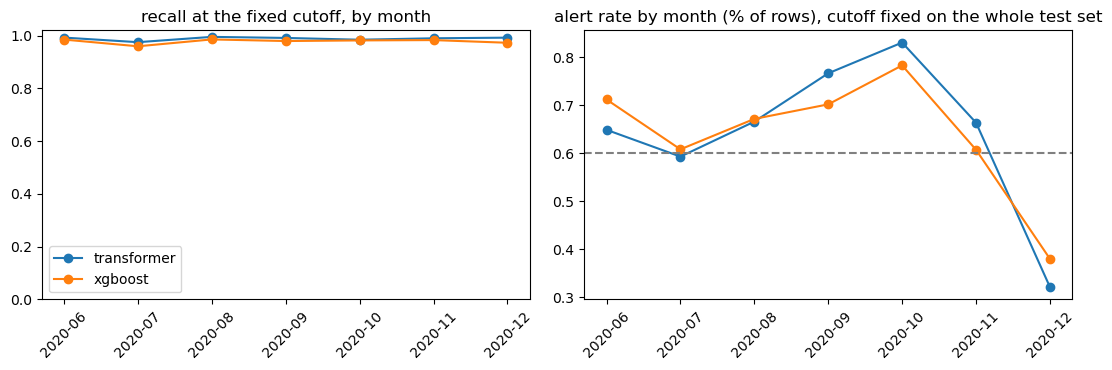

field,n_tokens,psi train vs test,psi train vs val,reading
TX,1,0.0000,0.0000,stable
DT,12,0.0210,0.0131,stable
HOUR,6,0.0000,0.0000,stable
CAT,14,0.0000,0.0001,stable
MER,501,0.0014,0.0065,stable
AMT,20,0.0002,0.0003,stable
DIST,8,0.0000,0.0001,stable


In [4]:
import matplotlib.pyplot as plt
ts_t = test["ts"].to_numpy()
monthly = {n: monthly_metrics(yt, scores[n][0], ct, ts_t, ALERT) for n in ("transformer", "xgboost") if scores[n]}
m = monthly["transformer"][["month", "n", "n_fraud", "fraud_rate"]].copy()
for n, t in monthly.items():
    for c in ("alert_rate", "recall_at_cutoff", "fp_ratio", "pr_auc"): m[f"{c} {n[:3]}"] = t[c].to_numpy()
display(m.style.format({c: "{:.3f}" for c in m if c not in ("month", "n", "n_fraud")}).format({"n": "{:,}", "fraud_rate": "{:.2%}"}).hide(axis="index"))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for n, t in monthly.items():
    ax[0].plot(t["month"], t["recall_at_cutoff"], marker="o", label=n); ax[1].plot(t["month"], t["alert_rate"] * 100, marker="o", label=n)
ax[0].set_title("recall at the fixed cutoff, by month"); ax[0].set_ylim(0, 1.02); ax[0].legend()
ax[1].set_title("alert rate by month (% of rows), cutoff fixed on the whole test set"); ax[1].axhline(ALERT * 100, ls="--", c="gray")
for a in ax: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); fig.savefig(f"{RES}/06a_monthly.png", dpi=120); plt.show()

psi_tt = psi_by_field(ids_all[split == "train"], ids_all[te], FIELDS).rename(columns={"psi": "psi train vs test"})
psi_tv = psi_by_field(ids_all[split == "train"], ids_all[split == "val"], FIELDS)["psi"].to_numpy()
psi_tt["psi train vs val"] = psi_tv
psi_tt["reading"] = np.select([psi_tt["psi train vs test"] < 0.1, psi_tt["psi train vs test"] < 0.25], ["stable", "moderate shift"], "major shift")
display(psi_tt.style.format({"psi train vs test": "{:.4f}", "psi train vs val": "{:.4f}"}).hide(axis="index"))

## Stage 6a-4: subgroups

Recall at the fixed cutoff per group, both models side by side; groups with fewer than 20 test frauds are dropped because a recall over 5 frauds is noise. Three cuts: transaction category; how much history the card had at that moment (rows before it, over the whole parquet, the same quantity the transformer's window and XGBoost's rolling features see); and the cardholder attributes from `cards.parquet`, joined here for the first time and never used as a feature. Young cards ("0" and "1-4") are the risk the guide names: a sequence model with nothing to read.

In [5]:
feats = build_features(df)                                                  # step-5 features, for hist_n and the error tables
pos_t = history_length(card)[te]
groups = {"category": test["category"].to_numpy(), "history rows before": history_bucket(pos_t)}
ATTRS = [c for c in ("gender", "age_bucket", "city_pop_bucket") if c in cards.columns]
if "card_id" in cards.columns and ATTRS:
    ct_attr = test[["card_id"]].merge(cards, on="card_id", how="left")
    for c in ATTRS:
        groups[c] = ct_attr[c].fillna("unknown").to_numpy()
else:
    print("cards.parquet has no cardholder attributes (columns:", list(cards.columns), "); it is the older per-card stats table. "
          "Rerun step 1's card_table to get gender / age_bucket / city_pop_bucket; the cardholder cuts are skipped.")

def side_by_side(g, min_fraud=20):
    out = None
    for n in ("transformer", "xgboost"):
        s = subgroup_metrics(yt, scores[n][0], ct, g, ALERT, min_fraud=min_fraud)[["group", "n", "n_fraud", "recall_at_cutoff", "alert_rate", "pr_auc"]]
        s = s.rename(columns={"recall_at_cutoff": f"recall {n[:3]}", "alert_rate": f"alert rate {n[:3]}", "pr_auc": f"pr_auc {n[:3]}"})
        out = s if out is None else out.merge(s, on=["group", "n", "n_fraud"], how="outer")
    if out is not None and len(out) and "recall tra" in out and "recall xgb" in out:
        out["recall gap (tra - xgb)"] = out["recall tra"] - out["recall xgb"]
    return out

sub = {}
for name, g in groups.items():
    sub[name] = side_by_side(g)
    print(f"\n== by {name} ==  ({len(sub[name]) if sub[name] is not None else 0} groups with >= 20 test frauds)")
    if sub[name] is not None and len(sub[name]):
        order = ["0", "1-4", "5-11", "12-31", "32+"] if name == "history rows before" else None
        t = sub[name].set_index("group").loc[[o for o in order if o in sub[name]["group"].values]].reset_index() if order else sub[name]
        display(t.style.format({c: "{:.3f}" for c in t if c not in ("group", "n", "n_fraud")}).format({"n": "{:,}"}).hide(axis="index"))


== by category ==  (14 groups with >= 20 test frauds)


group,n,n_fraud,recall tra,alert rate tra,pr_auc tra,recall xgb,alert rate xgb,pr_auc xgb,recall gap (tra - xgb)
entertainment,"40,104",59,1.000000,0.002419,0.986798,0.983051,0.002444,0.991384,0.016949
food_dining,"39,268",54,0.944444,0.002445,0.923975,0.925926,0.003463,0.794385,0.018519
gas_transport,"56,370",154,1.000000,0.003832,0.989037,1.000000,0.003211,0.997259,0.000000
grocery_net,"19,426",41,1.000000,0.007464,0.968616,0.975610,0.006898,0.929456,0.024390
grocery_pos,"52,553",485,1.000000,0.011493,0.999555,1.000000,0.009743,0.999916,0.000000
health_fitness,"36,674",52,0.961538,0.002454,0.958225,0.942308,0.003708,0.878518,0.019231
home,"52,345",67,1.000000,0.002560,0.985837,0.925373,0.002808,0.901142,0.074627
kids_pets,"48,692",65,0.969231,0.003122,0.945872,0.907692,0.003471,0.790378,0.061538
misc_net,"27,367",267,0.992509,0.013483,0.990603,0.992509,0.015018,0.986775,0.000000
misc_pos,"34,574",72,0.986111,0.005843,0.952724,0.930556,0.006421,0.891030,0.055556



== by history rows before ==  (3 groups with >= 20 test frauds)


group,n,n_fraud,recall tra,alert rate tra,pr_auc tra,recall xgb,alert rate xgb,pr_auc xgb,recall gap (tra - xgb)
1-4,64,64,1.000000,1.000000,nan,1.000000,1.000000,nan,0.000000
5-11,81,81,1.000000,1.000000,nan,1.000000,1.000000,nan,0.000000
32+,"555,556",1982,0.987891,0.005710,0.984783,0.976287,0.005708,0.972449,0.011604



== by gender ==  (2 groups with >= 20 test frauds)


group,n,n_fraud,recall tra,alert rate tra,pr_auc tra,recall xgb,alert rate xgb,pr_auc xgb,recall gap (tra - xgb)
F,"304,886",1164,0.981959,0.006471,0.978794,0.970790,0.006160,0.963841,0.011168
M,"250,833",981,0.995923,0.005426,0.993395,0.986748,0.005805,0.987825,0.009174



== by age_bucket ==  (6 groups with >= 20 test frauds)


group,n,n_fraud,recall tra,alert rate tra,pr_auc tra,recall xgb,alert rate xgb,pr_auc xgb,recall gap (tra - xgb)
25-34,"113,435",417,0.990408,0.006770,0.986656,0.983213,0.006074,0.973218,0.007194
35-44,"122,214",386,0.992228,0.005875,0.983036,0.981865,0.005474,0.965319,0.010363
45-54,"113,064",427,0.983607,0.005714,0.980290,0.964871,0.005820,0.963953,0.018735
55-64,"69,018",342,0.988304,0.006187,0.990646,0.976608,0.007085,0.979893,0.011696
65+,"88,157",410,0.987805,0.005604,0.987328,0.975610,0.006193,0.982999,0.012195
<25,"49,831",163,0.987730,0.005639,0.986810,1.000000,0.005679,0.992902,-0.012270



== by city_pop_bucket ==  (4 groups with >= 20 test frauds)


group,n,n_fraud,recall tra,alert rate tra,pr_auc tra,recall xgb,alert rate xgb,pr_auc xgb,recall gap (tra - xgb)
100k-1M,"61,870",169,1.000000,0.005738,0.990627,0.994083,0.005495,0.980642,0.005917
10k-100k,"89,844",384,0.981771,0.007502,0.981792,0.966146,0.007057,0.963448,0.015625
1M+,"14,046",39,1.000000,0.005411,1.000000,1.000000,0.005909,0.993676,0.000000
<10k,"389,959",1553,0.988410,0.005716,0.986338,0.978751,0.005839,0.977738,0.009659


## Stage 6a-5: error analysis, 20 + 20

Frauds that one model flags at its cutoff and the other does not, the 20 with the largest score gap each way. Each row shows the transaction, the step-5 history features that describe its context (how many earlier rows the card had, how far the amount is from the card's own mean, the gap to the previous transaction) and both scores; three of each side are decoded token by token, the card's previous 12 transactions and then the one being judged, so the pattern the model saw is visible. The medians table at the end is the summary: what the transformer-only catches look like versus the XGBoost-only catches versus all test fraud.

In [6]:
only_tf, only_xgb = disagreements(yt, A, B, ALERT, k=20)
cols = ["ts", "category", "merchant", "amt", "dist_km"]
fcols = ["hist_n", "amt_ratio_mean", "amt_z", "gap_prev_s", "n_24h", "hist_cat_share", "first_at_merchant"]
ft = feats[te].reset_index(drop=True)
def show(idx, title):
    print(f"\n== {title}: {len(idx)} rows ==")
    if not len(idx): return
    t = pd.concat([test.loc[idx, cols].reset_index(drop=True), ft.loc[idx, fcols].reset_index(drop=True)], axis=1)
    t.insert(0, "test_row", idx); t["score tra"] = A[idx]; t["score xgb"] = B[idx]
    display(t.style.format({"amt": "{:.2f}", "dist_km": "{:.1f}", "amt_ratio_mean": "{:.2f}", "amt_z": "{:.2f}", "gap_prev_s": "{:,.0f}", "hist_cat_share": "{:.2f}", "score tra": "{:.4f}", "score xgb": "{:.4f}"}).hide(axis="index"))
show(only_tf, "fraud flagged by the transformer only"); show(only_xgb, "fraud flagged by XGBoost only")

test_pos = np.flatnonzero(te)                                               # parquet row of each test row
def decode_history(i, H=12):
    r = test_pos[i]; first = r - min(pos_t[i], H)
    lines = []
    for q in range(first, r + 1):
        toks = tok.decode(ids_all[q]); mark = "  <- judged" if q == r else ""
        lines.append(f"  {df['ts'].iloc[q]:%m-%d %H:%M}  fraud={df['is_fraud'].iloc[q]}  {' '.join(toks[1:])}{mark}")
    return "\n".join(lines)
for title, idx in (("transformer only", only_tf[:3]), ("xgboost only", only_xgb[:3])):
    for i in idx:
        print(f"\n-- {title}: test row {i}, score tra {A[i]:.4f} xgb {B[i]:.4f} --\n{decode_history(i)}")

all_fraud = np.flatnonzero(yt == 1)
med = pd.DataFrame({"transformer only": ft.loc[only_tf, fcols + ['amt']].median() if len(only_tf) else np.nan,
                    "xgboost only": ft.loc[only_xgb, fcols + ['amt']].median() if len(only_xgb) else np.nan,
                    "all test fraud": ft.loc[all_fraud, fcols + ['amt']].median(),
                    "all test rows": ft[fcols + ['amt']].median()}).T
med.insert(0, "rows", [len(only_tf), len(only_xgb), len(all_fraud), len(ft)])
print("\nmedians of the context features in each set:"); display(med.style.format("{:.2f}").format({"rows": "{:,}", "gap_prev_s": "{:,.0f}", "hist_n": "{:.0f}"}))


== fraud flagged by the transformer only: 20 rows ==


test_row,ts,category,merchant,amt,dist_km,hist_n,amt_ratio_mean,amt_z,gap_prev_s,n_24h,hist_cat_share,first_at_merchant,score tra,score xgb
162595,2020-06-26 16:34:06,home,"fraud_Schiller, Blanda and Johnson",219.46,92.0,1559,3.36,1.15,"38,233",4,0.10,0,0.9999,0.0002
536283,2020-09-26 20:46:23,kids_pets,"fraud_Dare, Casper and Bartoletti",17.31,92.3,3109,0.19,-0.53,"31,867",5,0.08,0,0.9999,0.0004
39997,2020-09-23 19:28:16,misc_pos,"fraud_Monahan, Bogisich and Ledner",7.23,132.4,2445,0.13,-0.36,"55,951",4,0.06,0,0.9998,0.0004
455575,2020-10-11 12:18:53,travel,fraud_Tromp Group,1.78,96.7,1256,0.03,-0.61,"38,272",2,0.04,0,0.9998,0.0005
347022,2020-07-03 22:19:41,misc_pos,"fraud_Nienow, Ankunding and Collier",6.67,53.7,2580,0.10,-0.32,"45,828",3,0.07,0,0.9999,0.0025
533054,2020-12-10 23:47:48,home,"fraud_Wuckert, Wintheiser and Friesen",261.03,108.5,2778,2.97,1.28,"22,609",3,0.09,0,0.9998,0.0030
549203,2020-10-05 12:04:45,personal_care,"fraud_Medhurst, Cartwright and Ebert",21.74,62.7,3088,0.25,-0.48,"10,502",5,0.08,0,0.9998,0.0038
116411,2020-11-25 18:57:14,kids_pets,fraud_Berge-Hills,21.55,117.3,1338,0.30,-0.22,"33,896",6,0.09,0,0.9999,0.0049
437800,2020-07-20 23:10:36,personal_care,fraud_Erdman-Ebert,21.48,16.7,1659,0.25,-0.52,"2,255",2,0.08,0,0.9999,0.0054
228327,2020-11-04 15:39:16,personal_care,fraud_Osinski Inc,22.66,44.7,1952,0.25,-0.87,"49,378",2,0.04,1,0.9979,0.0038



== fraud flagged by XGBoost only: 8 rows ==


test_row,ts,category,merchant,amt,dist_km,hist_n,amt_ratio_mean,amt_z,gap_prev_s,n_24h,hist_cat_share,first_at_merchant,score tra,score xgb
412834,2020-10-24 20:25:22,shopping_net,"fraud_Reichert, Shanahan and Hayes",1140.88,75.1,1274,16.10,15.19,"5,852",1,0.07,0,0.0138,0.9322
407533,2020-09-29 11:46:27,shopping_pos,"fraud_Baumbach, Strosin and Nicolas",1029.47,108.5,2472,11.58,7.65,"62,940",2,0.12,0,0.0036,0.7034
412833,2020-10-24 18:47:50,shopping_net,"fraud_Streich, Dietrich and Barton",966.98,88.6,1273,13.78,13.62,"106,842",0,0.07,0,0.0016,0.2429
193434,2020-11-04 00:19:40,misc_net,"fraud_Rohan, White and Aufderhar",801.34,27.8,1914,9.15,5.33,"20,581",5,0.05,0,0.0384,0.2443
409931,2020-09-20 09:22:52,misc_net,fraud_Block-Parisian,879.72,83.0,1205,10.05,7.26,"146,205",0,0.06,0,0.0099,0.0393
549197,2020-10-04 05:34:50,food_dining,"fraud_Lakin, Ferry and Beatty",107.67,46.0,3082,1.24,0.15,"16,969",4,0.08,0,0.0062,0.0292
292915,2020-07-18 21:00:49,personal_care,fraud_Gottlieb-Hansen,21.38,101.7,2191,0.23,-0.84,"144,843",0,0.04,0,0.0169,0.0127
368005,2020-10-31 17:36:06,travel,fraud_Lemke and Sons,10.53,113.1,0,nan,nan,nan,0,nan,1,0.0379,0.0244



-- transformer only: test row 162595, score tra 0.9999 xgb 0.0002 --
  06-23 22:31  fraud=0  DT_07 HOUR_NIGHT CAT_home MER_fraud_Moore, Williamson and Emmerich AMT_09 DIST_05
  06-24 02:01  fraud=0  DT_05 HOUR_LATE_NIGHT CAT_gas_transport MER_fraud_Schmitt Inc AMT_12 DIST_04
  06-24 07:38  fraud=0  DT_05 HOUR_EARLY_MORNING CAT_gas_transport MER_fraud_Streich, Hansen and Veum AMT_12 DIST_05
  06-24 09:44  fraud=0  DT_04 HOUR_MORNING CAT_shopping_net MER_fraud_Labadie, Treutel and Bode AMT_04 DIST_06
  06-24 14:11  fraud=0  DT_05 HOUR_AFTERNOON CAT_kids_pets MER_fraud_Bode-Schuster AMT_13 DIST_05
  06-24 18:42  fraud=0  DT_05 HOUR_EVENING CAT_travel MER_OTHER AMT_07 DIST_06
  06-25 03:49  fraud=0  DT_06 HOUR_LATE_NIGHT CAT_misc_pos MER_OTHER AMT_07 DIST_04
  06-25 05:12  fraud=0  DT_04 HOUR_EARLY_MORNING CAT_grocery_pos MER_fraud_Auer-Mosciski AMT_12 DIST_06
  06-25 22:13  fraud=0  DT_07 HOUR_NIGHT CAT_kids_pets MER_fraud_Pouros, Walker and Spencer AMT_12 DIST_05
  06-26 01:35  fraud=1 

,rows,hist_n,amt_ratio_mean,amt_z,gap_prev_s,n_24h,hist_cat_share,first_at_merchant,amt
transformer only,20,2262,0.267388,-0.330346,"32,882",3.500000,0.071379,0.000000,21.515000
xgboost only,8,1594,10.050238,7.264985,"62,940",0.500000,0.069128,0.000000,840.530000
all test fraud,"2,145",1398,5.511477,2.361674,"4,945",4.000000,0.078197,0.000000,371.940000
all test rows,"555,719",2139,0.668518,-0.178554,"13,876",4.000000,0.080858,0.000000,47.290000


## Stage 6a-6: the ceiling, or the Sparkov caveat in numbers

Sparkov generates fraud from rules, so a model can learn the rules. Two numbers make the caveat concrete: how much of the test fraud each model scores above 0.99, and how far the typical fraud amount sits from the typical normal amount. When most fraud is trivially separable, the report has to say that the absolute levels carry little information and that the comparison lives in the fixed-alert-rate gaps, the subgroup gaps and the ablation trends.

In [7]:
ceiling = {}
for n, v in scores.items():
    if v:
        s = v[0]; c = global_cutoff(s, ALERT)
        ceiling[n] = {"fraud scored > 0.99": float((s[yt == 1] > 0.99).mean()), "cutoff at 0.6% alerts": float(c),
                      "normals above cutoff": float((s[yt == 0] >= c).mean())}
display(pd.DataFrame(ceiling).T.style.format({"fraud scored > 0.99": "{:.1%}", "cutoff at 0.6% alerts": "{:.4f}", "normals above cutoff": "{:.3%}"}))
amt = {"fraud median amt": float(test.loc[yt == 1, "amt"].median()), "normal median amt": float(test.loc[yt == 0, "amt"].median()),
       "fraud share with amt > 200": float((test.loc[yt == 1, "amt"] > 200).mean()), "normal share with amt > 200": float((test.loc[yt == 0, "amt"] > 200).mean())}
print({k: round(v, 3) for k, v in amt.items()})

,fraud scored > 0.99,cutoff at 0.6% alerts,normals above cutoff
transformer,95.7%,0.0470,0.219%
transformer scratch,83.4%,0.4998,0.236%
xgboost,73.8%,0.0112,0.223%
xgboost current-only,41.4%,0.7379,0.289%


{'fraud median amt': 371.94, 'normal median amt': 47.15, 'fraud share with amt > 200': 0.751, 'normal share with amt > 200': 0.043}


## Stage 6a-7: save 06a_validate.json

In [8]:
def records(d): return None if d is None else d.replace([np.inf, -np.inf], np.nan).to_dict(orient="records")
out = {"alert_rate": ALERT, "n_test": int(len(yt)), "n_test_fraud": int(yt.sum()), "pair": "transformer pretrained_H12 seed0 vs xgboost full seed0",
       "bootstrap": boot, "seed_pairs": records(pairs), "monthly": {n: records(t) for n, t in monthly.items()}, "psi": records(psi_tt),
       "subgroups": {n: records(t) for n, t in sub.items()},
       "disagreements": {"transformer_only": [int(i) for i in only_tf], "xgboost_only": [int(i) for i in only_xgb], "medians": med.to_dict(orient="index")},
       "ceiling": ceiling, "amount_separation": amt, "runtime": describe()}
with open(f"{RES}/06a_validate.json", "w") as f:
    json.dump(out, f, indent=2, default=float)
print("saved 06a_validate.json:", list(out))

saved 06a_validate.json: ['alert_rate', 'n_test', 'n_test_fraud', 'pair', 'bootstrap', 'seed_pairs', 'monthly', 'psi', 'subgroups', 'disagreements', 'ceiling', 'amount_separation', 'runtime']


## What to read off the numbers

- The bootstrap interval is the one sentence the report needs about transformer versus XGBoost. If it excludes zero, the lead is real at this test size; if it includes zero, the honest statement is that the two models are tied on this data, and the cost comparison from step 5 decides.
- Monthly: alert rate per month is the operational number. A cutoff fixed on the whole period can fire far more in one month than another; a validator asks whether the alert budget would have been blown. Recall per month tells whether the model's edge holds in every month or comes from one.
- PSI: Sparkov has no real drift to find; the expected reading is "stable" on every field, with the test period's own calendar (hour, weekday) the only mover. On real data this table is where a model gets sent back before it is scored.
- Subgroups: the "0" and "1-4" history buckets are the ones to quote. WF's claim that long history is the biggest driver has a mirror image: a card with no history gives the sequence model nothing, and the gap to XGBoost there is the deployment risk.
- Error analysis: the medians table, not the individual rows, is the finding. Which context features separate the transformer-only catches from the XGBoost-only catches says what each model reads.
- Ceiling: if most fraud scores above 0.99 for every model, write that the levels are saturated and point the reader to the gaps and the ablations, as the guide says.

## Push results and this notebook back to GitHub

In [9]:
import shutil, glob, os, json
os.makedirs("results/metrics", exist_ok=True); os.makedirs("results/figures", exist_ok=True)
for f in glob.glob(f"{ROOT}/results/*.json"):
    shutil.copy(f, "results/metrics/")
for f in glob.glob(f"{ROOT}/results/*.png"):
    shutil.copy(f, "results/figures/")
if on_colab():
    def same_code(a, b):   # a Drive notebook may be copied back only if its code cells equal the repo version
        cells = lambda p: ["".join(c["source"]) for c in json.load(open(p))["cells"] if c["cell_type"] == "code"]
        return cells(a) == cells(b)
    for f in glob.glob(f"{ROOT}/notebooks/*.ipynb"):   # outputs are kept so GitHub shows them
        repo = f"notebooks/{os.path.basename(f)}"
        if not os.path.exists(repo) or same_code(f, repo):
            shutil.copy(f, repo)
        else:
            print("STALE, not copied:", os.path.basename(f), "-> delete it from Drive and rerun the setup cell")
    !git config user.email "linboyy@hotmail.com" && git config user.name "Bo Lin"
    !git add results notebooks && git commit -q -m "results and notebooks from Colab" && git push -q
    !git log --oneline | head -1
else:
    print("laptop: results copied into results/; this notebook file already is the repo copy; commit from the terminal")
    !git status --short results notebooks

laptop: results copied into results/; this notebook file already is the repo copy; commit from the terminal
 M notebooks/06a_validate.ipynb
 M notebooks/06b_ablations.ipynb
?? results/figures/06a_monthly.png
?? results/metrics/06a_validate.json


In [10]:
if on_colab():
    drive.flush_and_unmount()